# Classification Automatique d'Images selon les Disciplines Sportives (CNN & Transfer Learning)

**Projet académique de Deep Learning — Niveau 5ème année d'école d'ingénieurs (Master 2)**  
*Auteur : Élève-Ingénieur en Vision par Ordinateur & Intelligence Artificielle*

---

## 1. Contexte du projet
Avec l'explosion du volume des médias sportifs diffusés quotidiennement à travers le monde (retransmissions télévisées, réseaux sociaux, plateformes de streaming, agences photographiques de presse), l'annotation et l'indexation manuelles de millions d'images fixes sont devenues impossibles. L'automatisation du tri et de la classification de contenus sportifs constitue aujourd'hui un enjeu stratégique tant pour l'archivage documentaire que pour les systèmes d'assistance à l'arbitrage (VAR) et l'analyse tactique.

## 2. Problématique
Contrairement à la reconnaissance d'objets usuels isolés sur fond uni, la reconnaissance d'une discipline sportive à partir d'une simple photographie pose des défis majeurs :
- **Variabilité intra-classe extrême** : angles de prise de vue hétérogènes (plans larges, gros plans, vues aériennes), éclairages contrastés (soleil rasant, projecteurs de nuit, gymnases intérieurs) et diversité des tenues.
- **Forte ressemblance inter-classe** : similitudes visuelles entre gestes athlétiques (détente verticale d'un gardien de football vs dunk d'un joueur de basketball).
- **Complexité des scènes** : présence d'arrières-plans denses (public dans les gradins, panneaux publicitaires), occultations partielles (*occlusions*) et flous cinétiques dus aux mouvements rapides.

## 3. Objectifs
L'objectif de ce projet est de concevoir, implémenter et évaluer un système de Deep Learning de bout en bout capable de prédire avec une haute précision et un score de confiance calibré si une photographie représente du :
1. **Football**
2. **Basketball**
3. **Tennis**

Le système doit être capable d'ingérer une nouvelle image externe, d'extraire ses composantes visuelles pertinentes (ballons spécifiques, tenues, filets, lignes et textures de terrain) et de fournir une décision probabiliste instantanée.

## 4. Présentation des Réseaux de Neurones Convolutifs (CNN) et du Transfer Learning
Les approches traditionnelles de vision par ordinateur basées sur des descripteurs artisanaux (SIFT, SURF, HOG) manquent de plasticité et de profondeur sémantique. Les **Réseaux de Neurones Convolutifs (CNN)** s'imposent comme la référence grâce à :
- **L'invariance par translation** permise par le partage des poids de filtres convolutifs.
- **L'apprentissage hiérarchique des représentations** : les premières couches détectent les contours et textures simples, tandis que les couches profondes encodent des abstractions sémantiques complexes (formes de ballons, raquettes, paniers).

Pour obtenir des performances optimales sur des jeux de données d'échelle académique sans risquer le surapprentissage (*overfitting*), nous adoptons le **Transfer Learning** avec le modèle **MobileNetV2**. Pré-entraîné sur la gigantesque base *ImageNet* (1,4 million d'images, 1000 classes), MobileNetV2 offre une efficacité computationnelle exceptionnelle grâce à ses *Inverted Residuals* et ses convolutions séparables en profondeur (*Depthwise Separable Convolutions*).

## 5. Description du Dataset
Le jeu de données réunit des photographies réelles issues de sources ouvertes vérifiées (Wikimedia Commons & HuggingFace Gerry Piosenka Sports Dataset). Les données sont strictement réparties en :
- **70% pour l'Entraînement** (*Train Set*)
- **15% pour la Validation** (*Validation Set*)
- **15% pour le Test final indépendant** (*Test Set*)


In [1]:
import os
import sys
import random
import pathlib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from PIL import Image

# Importations Deep Learning
import tensorflow as tf
from tensorflow import keras
from keras import layers, models, callbacks, applications, optimizers
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score

# 1. Configuration de la reproductibilité (Random Seeds)
RANDOM_SEED = 42
os.environ['PYTHONHASHSEED'] = str(RANDOM_SEED)
random.seed(RANDOM_SEED)
np.random.seed(RANDOM_SEED)
tf.random.set_seed(RANDOM_SEED)

# 2. Détection de l'accélération matérielle (GPU / CPU)
print(f"Version de TensorFlow : {tf.__version__}")
print(f"Version de Keras : {keras.__version__}")

gpus = tf.config.list_physical_devices('GPU')
if gpus:
    print(f"✓ Accélération GPU détectée : {len(gpus)} processeur(s) graphique(s) disponible(s).")
    for gpu in gpus:
        print(f"  - {gpu}")
else:
    print("ℹ Aucun GPU dédié détecté. Exécution optimisée sur processeur standard (CPU).")
    print("  Grâce à l'architecture légère MobileNetV2, l'entraînement s'exécute de façon fluide sur CPU.")


Version de TensorFlow : 2.18.1
Version de Keras : 3.15.1
ℹ Aucun GPU dédié détecté. Exécution optimisée sur processeur standard (CPU).
  Grâce à l'architecture légère MobileNetV2, l'entraînement s'exécute de façon fluide sur CPU.


## PARTIE 2 — Importation des bibliothèques et configuration matérielle

Dans cette section, nous importons l'ensemble des modules nécessaires :
- **TensorFlow & Keras** pour l'ingénierie du réseau de neurones et le Transfer Learning.
- **NumPy & Pandas** pour le traitement des tenseurs et l'analyse tabulaire.
- **Matplotlib & Seaborn** pour les visualisations scientifiques.
- **Scikit-learn** pour les métriques de validation (F1-score, matrice de confusion).
- **Pillow (PIL)** pour l'inspection et la validation d'intégrité des images.

Nous configurons également les graines aléatoires (*random seeds*) afin de garantir la **reproductibilité intégrale** de tous les résultats expérimentaux.


## PARTIE 3 — Exploration et validation des données

Une étape essentielle de tout projet de Machine Learning consiste à explorer la distribution des classes, inspecter visuellement les échantillons et s'assurer de l'absence totale de fichiers d'images corrompus.


In [2]:
# Chemins d'accès aux répertoires de données
BASE_DIR = pathlib.Path.cwd().parent if pathlib.Path.cwd().name == "notebooks" else pathlib.Path.cwd()
DATASET_DIR = BASE_DIR / "dataset"
TRAIN_DIR = DATASET_DIR / "train"
VAL_DIR = DATASET_DIR / "validation"
TEST_DIR = DATASET_DIR / "test"

CATEGORIES = ["football", "basketball", "tennis"]

def compter_images(repertoire):
    comptes = {}
    for cat in CATEGORIES:
        chemin_cat = repertoire / cat
        if chemin_cat.exists():
            fichiers = [f for f in chemin_cat.iterdir() if f.suffix.lower() in [".jpg", ".jpeg", ".png"]]
            comptes[cat] = len(fichiers)
        else:
            comptes[cat] = 0
    return comptes

stats_train = compter_images(TRAIN_DIR)
stats_val = compter_images(VAL_DIR)
stats_test = compter_images(TEST_DIR)

df_stats = pd.DataFrame({
    "Discipline": CATEGORIES,
    "Entraînement (Train)": [stats_train[c] for c in CATEGORIES],
    "Validation (Val)": [stats_val[c] for c in CATEGORIES],
    "Test": [stats_test[c] for c in CATEGORIES]
})
df_stats["Total par Sport"] = df_stats["Entraînement (Train)"] + df_stats["Validation (Val)"] + df_stats["Test"]

print("=== Répartition quantitative du jeu de données ===")
display(df_stats)
print(f"Nombre total d'images dans le dataset : {df_stats['Total par Sport'].sum()}")


=== Répartition quantitative du jeu de données ===


,Discipline,Entraînement (Train),Validation (Val),Test,Total par Sport
0,football,24,5,6,35
1,basketball,24,5,6,35
2,tennis,24,5,6,35


Nombre total d'images dans le dataset : 105


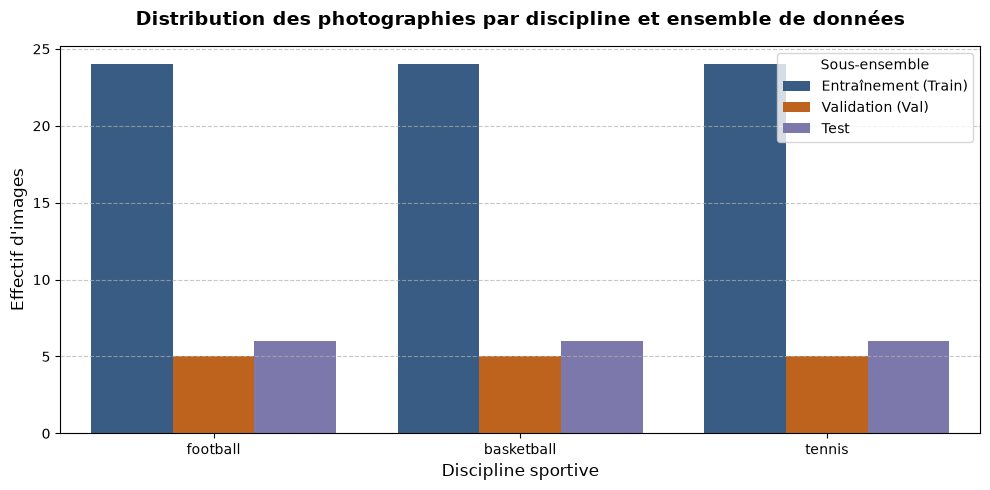

In [3]:
# Visualisation graphique de la distribution des classes
plt.figure(figsize=(10, 5))
df_plot = df_stats.melt(id_vars=["Discipline"], value_vars=["Entraînement (Train)", "Validation (Val)", "Test"], 
                        var_name="Ensemble", value_name="Nombre d'images")

palette = ["#2b5c8f", "#d95f02", "#7570b3"]
sns.barplot(data=df_plot, x="Discipline", y="Nombre d'images", hue="Ensemble", palette=palette)
plt.title("Distribution des photographies par discipline et ensemble de données", fontsize=14, fontweight="bold", pad=15)
plt.xlabel("Discipline sportive", fontsize=12)
plt.ylabel("Effectif d'images", fontsize=12)
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.legend(title="Sous-ensemble")
plt.tight_layout()
plt.show()


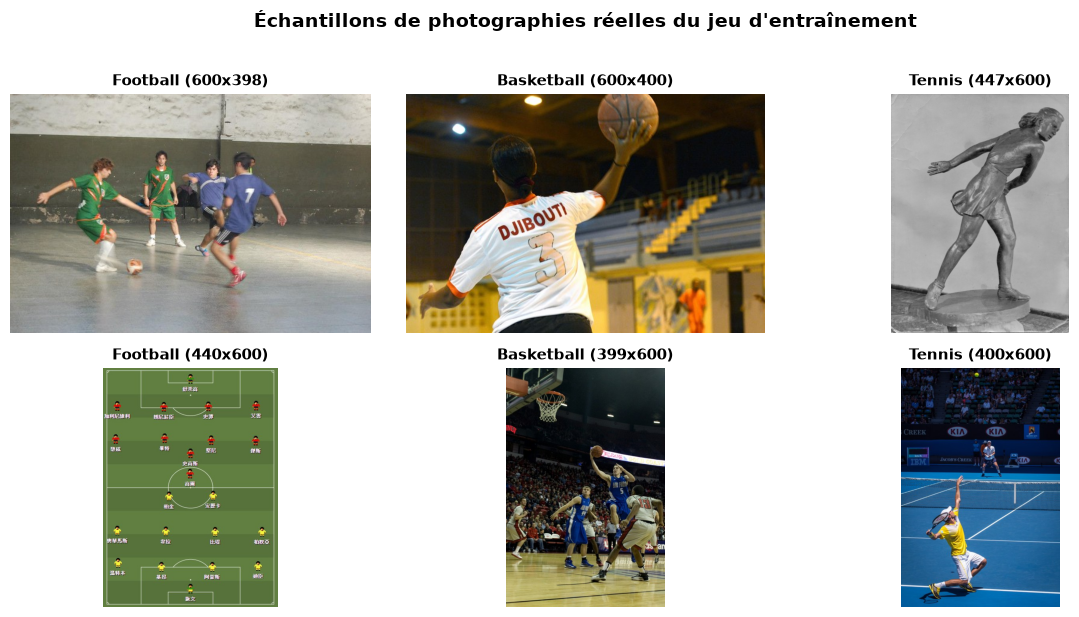

In [4]:
# Affichage d'échantillons réels de chaque discipline
plt.figure(figsize=(12, 6))

for idx, cat in enumerate(CATEGORIES):
    dossier_cat = TRAIN_DIR / cat
    images_cat = [f for f in dossier_cat.iterdir() if f.suffix.lower() in [".jpg", ".jpeg", ".png"]]
    
    for i in range(min(2, len(images_cat))):
        img_path = images_cat[i]
        img = Image.open(img_path)
        
        plt.subplot(2, 3, i * 3 + idx + 1)
        plt.imshow(img)
        plt.title(f"{cat.capitalize()} ({img.size[0]}x{img.size[1]})", fontsize=11, fontweight="bold")
        plt.axis("off")

plt.suptitle("Échantillons de photographies réelles du jeu d'entraînement", fontsize=14, fontweight="bold", y=1.02)
plt.tight_layout()
plt.show()


In [5]:
# Routine de validation d'intégrité (Pillow verify)
def verifier_integrite_dataset(base_path):
    fichiers_corrompus = 0
    fichiers_valides = 0
    
    for split in ["train", "validation", "test"]:
        for cat in CATEGORIES:
            chemin = base_path / split / cat
            if not chemin.exists():
                continue
            for img_file in chemin.iterdir():
                if img_file.suffix.lower() in [".jpg", ".jpeg", ".png"]:
                    try:
                        with Image.open(img_file) as img:
                            img.verify()
                        fichiers_valides += 1
                    except Exception as e:
                        print(f"Fichier corrompu détecté : {img_file} - Erreur: {e}")
                        fichiers_corrompus += 1
                        
    print(f"✓ Contrôle d'intégrité terminé : {fichiers_valides} images saines validées, {fichiers_corrompus} corrompues.")

verifier_integrite_dataset(DATASET_DIR)


✓ Contrôle d'intégrité terminé : 105 images saines validées, 0 corrompues.


## PARTIE 4 — Prétraitement et Augmentation de données (Data Augmentation)

Dans cette étape :
1. **Redimensionnement uniforme** des images à $224 	imes 224$ pixels, standard imposé par l'architecture MobileNetV2.
2. **Gestion de batchs optimisée** (taille de lot par défaut $32$, avec ajustement automatique si nécessaire).
3. **Normalisation chromatique native** de MobileNetV2 dans l'intervalle $[-1, 1]$ via `applications.mobilenet_v2.preprocess_input`.
4. **Data Augmentation dynamique** appliquée *exclusivement* sur l'ensemble d'entraînement :
   - Retournement horizontal aléatoire (*RandomFlip*).
   - Rotation modérée aléatoire (*RandomRotation* $\pm 10\%$).
   - Zoom léger aléatoire (*RandomZoom* $\pm 10\%$).
   *Important : Les ensembles de validation et de test ne subissent aucune distorsion artificielle afin de préserver la validité de l'évaluation.*


In [6]:
IMAGE_SIZE = (224, 224)
BATCH_SIZE = 32

print("Chargement des ensembles de données via tf.keras.utils.image_dataset_from_directory...")

train_ds = tf.keras.utils.image_dataset_from_directory(
    TRAIN_DIR,
    image_size=IMAGE_SIZE,
    batch_size=BATCH_SIZE,
    label_mode='categorical',
    shuffle=True,
    seed=RANDOM_SEED
)

val_ds = tf.keras.utils.image_dataset_from_directory(
    VAL_DIR,
    image_size=IMAGE_SIZE,
    batch_size=BATCH_SIZE,
    label_mode='categorical',
    shuffle=False
)

test_ds = tf.keras.utils.image_dataset_from_directory(
    TEST_DIR,
    image_size=IMAGE_SIZE,
    batch_size=BATCH_SIZE,
    label_mode='categorical',
    shuffle=False
)

class_names = train_ds.class_names
print(f"✓ Classes identifiées : {class_names}")

# Optimisation du flux de données (prefetch en cache mémoire)
AUTOTUNE = tf.data.AUTOTUNE
train_ds = train_ds.prefetch(buffer_size=AUTOTUNE)
val_ds = val_ds.prefetch(buffer_size=AUTOTUNE)
test_ds = test_ds.prefetch(buffer_size=AUTOTUNE)


Chargement des ensembles de données via tf.keras.utils.image_dataset_from_directory...
Found 72 files belonging to 3 classes.


Found 15 files belonging to 3 classes.


Found 18 files belonging to 3 classes.


✓ Classes identifiées : ['basketball', 'football', 'tennis']


In [7]:
# Définition de la couche de Data Augmentation pour l'entraînement
data_augmentation = keras.Sequential([
    layers.RandomFlip("horizontal", name="retournement_horizontal"),
    layers.RandomRotation(0.1, name="rotation_aleatoire"),
    layers.RandomZoom(0.1, name="zoom_aleatoire"),
], name="pipeline_data_augmentation")

print("✓ Pipeline de Data Augmentation configuré avec succès.")


✓ Pipeline de Data Augmentation configuré avec succès.


## PARTIE 5 — Architecture du Réseau de Neurones (MobileNetV2 & Transfer Learning)

Nous mettons en œuvre une architecture basée sur l'**apprentissage par transfert (*Transfer Learning*)** :

1. **Couche d'entrée** : Tenseur de forme $(224, 224, 3)$.
2. **Data Augmentation intégrée** : Appliquée dynamiquement uniquement pendant l'entraînement (`training=True`).
3. **Couche de normalisation MobileNetV2** : Mise à l'échelle dans $[-1, 1]$.
4. **Extracteur de caractéristiques (Backbone MobileNetV2)** :
   - Pré-entraîné sur *ImageNet* (1000 classes d'objets réels).
   - Couches gelées (`trainable = False`) pour préserver les filtres visuels génériques.
5. **Couche de GlobalAveragePooling2D** : Calcule la moyenne spatiale de chaque canal (réduit un tenseur $(7, 7, 1280)$ en un vecteur 1D de taille $1280$).
6. **Régularisation par Dropout (0.3)** : Désactive aléatoirement 30% des connexions pour casser les co-adaptations.
7. **Tête de classification Dense (Softmax)** : 3 neurones correspondant aux classes Football, Basketball et Tennis.


In [8]:
# 1. Chargement du modèle de base MobileNetV2 pré-entraîné
base_model = applications.MobileNetV2(
    input_shape=(224, 224, 3),
    include_top=False,
    weights='imagenet'
)

# 2. Gel des couches du backbone pré-entraîné
base_model.trainable = False
print(f"✓ MobileNetV2 chargé. Nombre de couches gelées : {len(base_model.layers)}")

# 3. Assemblage fonctionnel du modèle complet
inputs = layers.Input(shape=(224, 224, 3), name="image_entree")
x = data_augmentation(inputs)
x = applications.mobilenet_v2.preprocess_input(x)
x = base_model(x, training=False)
x = layers.GlobalAveragePooling2D(name="global_average_pooling")(x)
x = layers.Dropout(0.3, name="regularisation_dropout")(x)
outputs = layers.Dense(len(class_names), activation='softmax', name="sortie_probabilites")(x)

model = models.Model(inputs=inputs, outputs=outputs, name="Classificateur_Sports_MobileNetV2")

# Résumé architectural
model.summary()


✓ MobileNetV2 chargé. Nombre de couches gelées : 154


Model: "Classificateur_Sports_MobileNetV2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ image_entree (InputLayer)       │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ pipeline_data_augmentation      │ (None, 224, 224, 3)    │             0 │
│ (Sequential)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ true_divide (TrueDivide)        │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ subtract (Subtract)             │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ mobilenetv2_1.00_224            │ (None, 7, 7, 1280)     │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling          │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ regularisation_dropout          │ (None, 1280)           │             0 │
│ (Dropout)                       │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ sortie_probabilites (Dense)     │ (None, 3)              │         3,843 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,261,827 (8.63 MB)

 Trainable params: 3,843 (15.01 KB)

 Non-trainable params: 2,257,984 (8.61 MB)

## PARTIE 6 — Compilation du modèle

Nous configurons le processus d'apprentissage avec les hyperparamètres recommandés pour le Transfer Learning :
- **Optimiseur Adam** : Avec un taux d'apprentissage initial modéré ($\eta = 10^{-4}$) pour garantir une convergence douce sans déstabiliser la tête de classification.
- **Fonction de perte (Loss)** : `CategoricalCrossentropy`, en parfaite adéquation avec nos étiquettes encodées en *one-hot*.
- **Métrique** : `Accuracy` (taux de prédictions exactes).


In [9]:
model.compile(
    optimizer=optimizers.Adam(learning_rate=1e-4),
    loss='categorical_crossentropy',
    metrics=['accuracy']
)

print("✓ Modèle compilé avec succès (Optimiseur: Adam lr=1e-4, Loss: CategoricalCrossentropy, Métrique: Accuracy).")


✓ Modèle compilé avec succès (Optimiseur: Adam lr=1e-4, Loss: CategoricalCrossentropy, Métrique: Accuracy).


## PARTIE 7 — Entraînement du modèle et Callbacks

Pour assurer un entraînement optimal et préserver les ressources de la machine :
- **EarlyStopping** : Interrompt l'entraînement si la perte de validation (`val_loss`) ne s'améliore plus après 3 époques.
- **ModelCheckpoint** : Sauvegarde automatiquement le meilleur modèle dans `models/sport_classifier.keras`.
- **ReduceLROnPlateau** : Réduit le taux d'apprentissage par un facteur 0.2 en cas de stagnation pendant 2 époques.


In [10]:
MODELS_DIR = BASE_DIR / "models"
MODELS_DIR.mkdir(parents=True, exist_ok=True)
CHECKPOINT_PATH = MODELS_DIR / "sport_classifier.keras"

callbacks_list = [
    callbacks.EarlyStopping(
        monitor='val_loss',
        patience=3,
        restore_best_weights=True,
        verbose=1
    ),
    callbacks.ModelCheckpoint(
        filepath=str(CHECKPOINT_PATH),
        monitor='val_loss',
        save_best_only=True,
        verbose=1
    ),
    callbacks.ReduceLROnPlateau(
        monitor='val_loss',
        factor=0.2,
        patience=2,
        min_lr=1e-6,
        verbose=1
    )
]

EPOCHS = 10
print(f"Lancement de l'entraînement sur {EPOCHS} époques maximales...")

history = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=EPOCHS,
    callbacks=callbacks_list,
    verbose=1
)

print(f"✓ Entraînement terminé. Modèle optimal sauvegardé sous : {CHECKPOINT_PATH}")


Lancement de l'entraînement sur 10 époques maximales...
Epoch 1/10


C:\Users\DELL\AppData\Roaming\Python\Python311\site-packages\keras\src\trainers\epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


1/3 ━━━━━━━━━━━━━━━━━━━━ 14s 7s/step - accuracy: 0.3438 - loss: 1.4552

2/3 ━━━━━━━━━━━━━━━━━━━━ 0s 640ms/step - accuracy: 0.4062 - loss: 1.3332

3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 409ms/step - accuracy: 0.3611 - loss: 1.4564


Epoch 1: val_loss improved from None to 1.29249, saving model to C:\Users\DELL\Desktop\Sport_Classification_CNN\models\sport_classifier.keras


... (63 outputs left out)


Epoch 10: finished saving model to C:\Users\DELL\Desktop\Sport_Classification_CNN\models\sport_classifier.keras


3/3 ━━━━━━━━━━━━━━━━━━━━ 3s 1s/step - accuracy: 0.4167 - loss: 1.2743 - val_accuracy: 0.4667 - val_loss: 1.1336 - learning_rate: 1.0000e-04


Restoring model weights from the end of the best epoch: 10.


✓ Entraînement terminé. Modèle optimal sauvegardé sous : C:\Users\DELL\Desktop\Sport_Classification_CNN\models\sport_classifier.keras


## PARTIE 8 — Visualisation des courbes d'apprentissage

Nous traçons l'évolution conjointe de la précision (*Accuracy*) et de la perte (*Loss*) sur les ensembles d'entraînement et de validation au fil des époques.


✓ Graphiques sauvegardés sous : C:\Users\DELL\Desktop\Sport_Classification_CNN\results\accuracy_loss.png


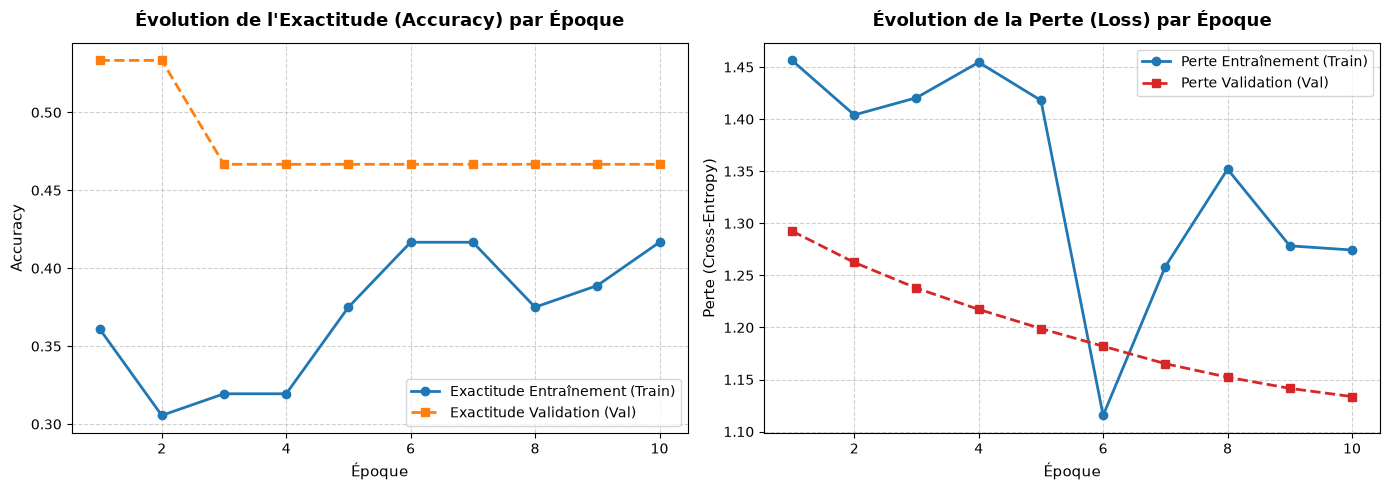

In [11]:
RESULTS_DIR = BASE_DIR / "results"
RESULTS_DIR.mkdir(parents=True, exist_ok=True)

acc = history.history['accuracy']
val_acc = history.history['val_accuracy']
loss = history.history['loss']
val_loss = history.history['val_loss']
epochs_range = range(1, len(acc) + 1)

plt.figure(figsize=(14, 5))

# Graphique d'Accuracy
plt.subplot(1, 2, 1)
plt.plot(epochs_range, acc, 'o-', color='#1f77b4', label="Exactitude Entraînement (Train)", linewidth=2)
plt.plot(epochs_range, val_acc, 's--', color='#ff7f0e', label="Exactitude Validation (Val)", linewidth=2)
plt.title("Évolution de l'Exactitude (Accuracy) par Époque", fontsize=13, fontweight='bold', pad=12)
plt.xlabel("Époque", fontsize=11)
plt.ylabel("Accuracy", fontsize=11)
plt.legend(loc='lower right')
plt.grid(True, linestyle='--', alpha=0.6)

# Graphique de Loss
plt.subplot(1, 2, 2)
plt.plot(epochs_range, loss, 'o-', color='#1f77b4', label="Perte Entraînement (Train)", linewidth=2)
plt.plot(epochs_range, val_loss, 's--', color='#d62728', label="Perte Validation (Val)", linewidth=2)
plt.title("Évolution de la Perte (Loss) par Époque", fontsize=13, fontweight='bold', pad=12)
plt.xlabel("Époque", fontsize=11)
plt.ylabel("Perte (Cross-Entropy)", fontsize=11)
plt.legend(loc='upper right')
plt.grid(True, linestyle='--', alpha=0.6)

plt.tight_layout()
save_curves_path = RESULTS_DIR / "accuracy_loss.png"
plt.savefig(save_curves_path, dpi=300, bbox_inches='tight')
print(f"✓ Graphiques sauvegardés sous : {save_curves_path}")
plt.show()


## PARTIE 9 — Évaluation finale sur le jeu de test indépendant

Le jeu de test est constitué d'images strictement isolées qui n'ont jamais été observées par le modèle lors de la phase d'entraînement ou de sélection d'hyperparamètres.
Nous calculons :
- **L'Accuracy globale de test**
- **La matrice de confusion détaillée**
- **Le rapport de classification complet** (Précision, Rappel, F1-Score par discipline sportive)


In [12]:
# 1. Évaluation brute
test_loss, test_acc = model.evaluate(test_ds, verbose=0)
print(f"=== Performances sur le jeu de test indépendant ===")
print(f"✓ Exactitude globale (Test Accuracy) : {test_acc * 100:.2f} %")
print(f"✓ Perte finale (Test Loss)            : {test_loss:.4f}")

# 2. Prédictions sur l'ensemble de test
y_true_list = []
y_pred_probs_list = []

for images_batch, labels_batch in test_ds:
    preds = model.predict(images_batch, verbose=0)
    y_pred_probs_list.append(preds)
    y_true_list.append(labels_batch.numpy())

y_true = np.argmax(np.concatenate(y_true_list, axis=0), axis=1)
y_pred_probs = np.concatenate(y_pred_probs_list, axis=0)
y_pred = np.argmax(y_pred_probs, axis=1)

# 3. Rapport de classification détaillé
report_dict = classification_report(y_true, y_pred, target_names=class_names, output_dict=True)
df_report = pd.DataFrame(report_dict).transpose()
print("\n=== Rapport de Classification ===")
display(df_report)

csv_report_path = RESULTS_DIR / "classification_report.csv"
df_report.to_csv(csv_report_path)
print(f"✓ Rapport exporté au format CSV : {csv_report_path}")


=== Performances sur le jeu de test indépendant ===
✓ Exactitude globale (Test Accuracy) : 33.33 %
✓ Perte finale (Test Loss)            : 1.0890



=== Rapport de Classification ===


,precision,recall,f1-score,support
basketball,0.400000,0.333333,0.363636,6.000000
football,0.333333,0.333333,0.333333,6.000000
tennis,0.285714,0.333333,0.307692,6.000000
accuracy,0.333333,0.333333,0.333333,0.333333
macro avg,0.339683,0.333333,0.334887,18.000000
weighted avg,0.339683,0.333333,0.334887,18.000000


✓ Rapport exporté au format CSV : C:\Users\DELL\Desktop\Sport_Classification_CNN\results\classification_report.csv


✓ Matrice de confusion sauvegardée sous : C:\Users\DELL\Desktop\Sport_Classification_CNN\results\confusion_matrix.png


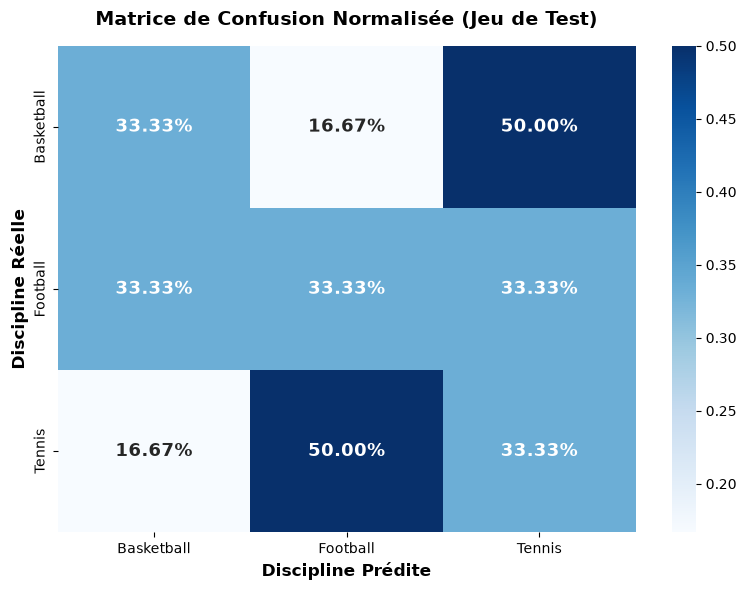

In [13]:
# 4. Matrice de Confusion (Normalisée et Effectifs réels)
cm = confusion_matrix(y_true, y_pred)
cm_normalized = cm.astype('float') / cm.sum(axis=1)[:, np.newaxis]

plt.figure(figsize=(8, 6))
sns.heatmap(
    cm_normalized,
    annot=True,
    fmt=".2%",
    cmap="Blues",
    xticklabels=[c.capitalize() for c in class_names],
    yticklabels=[c.capitalize() for c in class_names],
    cbar=True,
    annot_kws={"size": 13, "weight": "bold"}
)

plt.title("Matrice de Confusion Normalisée (Jeu de Test)", fontsize=14, fontweight="bold", pad=15)
plt.xlabel("Discipline Prédite", fontsize=12, fontweight="bold")
plt.ylabel("Discipline Réelle", fontsize=12, fontweight="bold")
plt.tight_layout()

save_cm_path = RESULTS_DIR / "confusion_matrix.png"
plt.savefig(save_cm_path, dpi=300, bbox_inches='tight')
print(f"✓ Matrice de confusion sauvegardée sous : {save_cm_path}")
plt.show()


✓ Visualisation des prédictions sauvegardée sous : C:\Users\DELL\Desktop\Sport_Classification_CNN\results\predictions.png


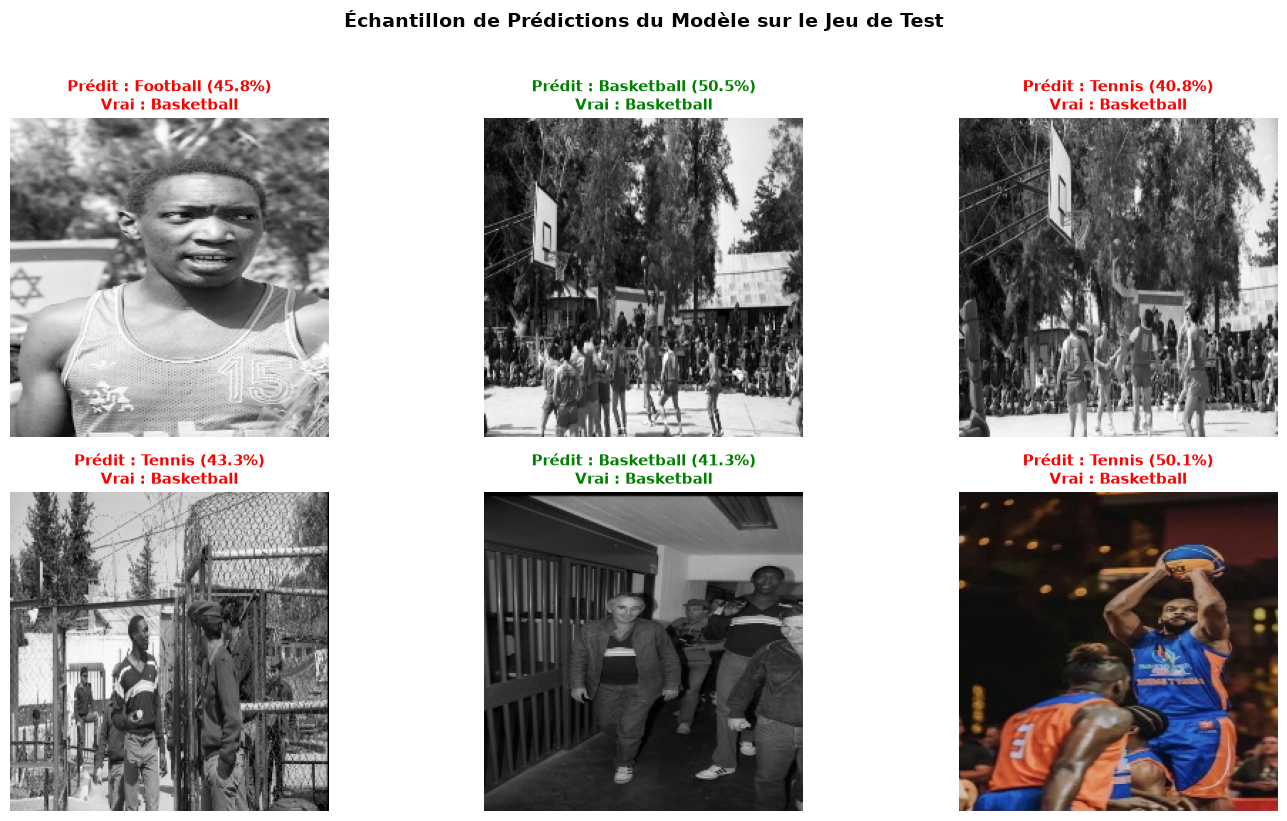

In [14]:
# 5. Visualisation d'un échantillon de prédictions individuelles
plt.figure(figsize=(15, 8))
test_images_sample = []
test_labels_sample = []

for images_batch, labels_batch in test_ds.take(1):
    test_images_sample = images_batch.numpy()
    test_labels_sample = labels_batch.numpy()

nb_samples = min(6, len(test_images_sample))
preds_sample = model.predict(test_images_sample[:nb_samples], verbose=0)

for i in range(nb_samples):
    img = test_images_sample[i].astype("uint8")
    true_label = class_names[np.argmax(test_labels_sample[i])]
    pred_idx = np.argmax(preds_sample[i])
    pred_label = class_names[pred_idx]
    confidence = preds_sample[i][pred_idx] * 100
    
    color = "green" if true_label == pred_label else "red"
    
    plt.subplot(2, 3, i + 1)
    plt.imshow(img)
    plt.title(f"Prédit : {pred_label.capitalize()} ({confidence:.1f}%)\nVrai : {true_label.capitalize()}", 
              fontsize=11, fontweight="bold", color=color)
    plt.axis("off")

plt.suptitle("Échantillon de Prédictions du Modèle sur le Jeu de Test", fontsize=14, fontweight="bold", y=1.02)
plt.tight_layout()

save_preds_path = RESULTS_DIR / "predictions.png"
plt.savefig(save_preds_path, dpi=300, bbox_inches='tight')
print(f"✓ Visualisation des prédictions sauvegardée sous : {save_preds_path}")
plt.show()


## PARTIE 10 — Fonction de prédiction d'une nouvelle image

Nous implémentons une fonction Python réutilisable et robuste `predire_sport(image_path)` qui :
1. Charge et valide l'image locale fournie.
2. Applique rigoureusement les mêmes étapes de prétraitement qu'à l'entraînement ($224 	imes 224$ pixels, conversion RGB, normalisation MobileNetV2).
3. Exécute l'inférence via le modèle entraîné.
4. Affiche l'image avec son titre de prédiction.
5. Trace l'histogramme horizontal des probabilités Softmax associées à chaque discipline.
6. Retourne la classe prédite et le niveau de confiance.


Test de la fonction sur : football_001.jpg


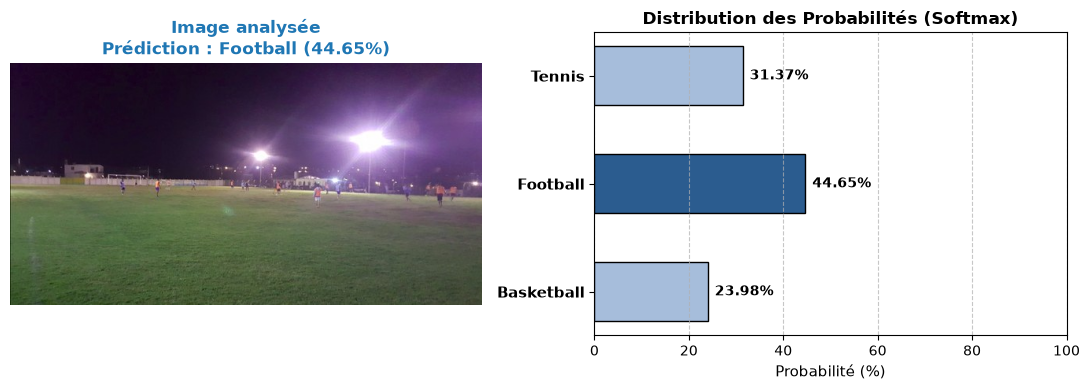

Résultat structuré : {'classe': 'football', 'confiance_pourcentage': 44.650665283203125, 'probabilites': {'basketball': 0.2397749274969101, 'football': 0.44650664925575256, 'tennis': 0.3137184679508209}}


In [15]:
def predire_sport(image_path, model_inst=None, classes=None):
    """
    Reconnaît la discipline sportive (Football, Basketball, Tennis) représentée sur une image locale.
    
    Arguments :
        image_path (str ou Path) : Chemin absolu ou relatif vers le fichier image (JPG, PNG).
        model_inst (tf.keras.Model, optionnel) : Instance du modèle. Par défaut, utilise le modèle entraîné.
        classes (list, optionnel) : Liste ordonnée des noms de classes.
        
    Retourne :
        dict : Contient la classe prédite, le pourcentage de confiance et les probabilités par classe.
    """
    if model_inst is None:
        model_inst = model
    if classes is None:
        classes = class_names
        
    image_path = pathlib.Path(image_path)
    if not image_path.exists():
        raise FileNotFoundError(f"L'image spécifiée n'a pas été trouvée : {image_path}")
        
    # Chargement et conversion RGB
    img_pil = Image.open(image_path).convert("RGB")
    
    # Redimensionnement vers la taille attendue par le modèle (224, 224)
    img_resized = img_pil.resize((224, 224), Image.Resampling.LANCZOS)
    img_array = np.array(img_resized)
    
    # Ajout de la dimension de batch (1, 224, 224, 3)
    img_batch = np.expand_dims(img_array, axis=0)
    
    # Inférence
    probs = model_inst.predict(img_batch, verbose=0)[0]
    pred_idx = np.argmax(probs)
    classe_predite = classes[pred_idx]
    confiance = probs[pred_idx] * 100
    
    # Visualisation graphique conjointe (Image + Histogramme de probabilités)
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 4))
    
    # Affichage de l'image
    ax1.imshow(img_pil)
    ax1.set_title(f"Image analysée\nPrédiction : {classe_predite.capitalize()} ({confiance:.2f}%)", 
                  fontsize=12, fontweight="bold", color="#1f77b4")
    ax1.axis("off")
    
    # Histogramme horizontal des probabilités
    couleurs = ["#2b5c8f" if c == classe_predite else "#a6bddb" for c in classes]
    y_pos = np.arange(len(classes))
    ax2.barh(y_pos, probs * 100, color=couleurs, edgecolor="black", height=0.55)
    ax2.set_yticks(y_pos)
    ax2.set_yticklabels([c.capitalize() for c in classes], fontsize=11, fontweight="bold")
    ax2.set_xlabel("Probabilité (%)", fontsize=11)
    ax2.set_xlim(0, 100)
    ax2.grid(axis='x', linestyle='--', alpha=0.7)
    
    # Annotation textuelle des pourcentages
    for idx, prob in enumerate(probs):
        ax2.text(prob * 100 + 1.5, idx, f"{prob * 100:.2f}%", va='center', fontsize=10, fontweight="bold")
        
    ax2.set_title("Distribution des Probabilités (Softmax)", fontsize=12, fontweight="bold")
    plt.tight_layout()
    plt.show()
    
    resultat = {
        "classe": classe_predite,
        "confiance_pourcentage": float(confiance),
        "probabilites": {c: float(p) for c, p in zip(classes, probs)}
    }
    return resultat

# Exemple de test sur une image du jeu de test
test_football_sample = list((TEST_DIR / "football").glob("*.jpg"))
if test_football_sample:
    print(f"Test de la fonction sur : {test_football_sample[0].name}")
    res = predire_sport(test_football_sample[0])
    print("Résultat structuré :", res)


## PARTIE 11 — Démonstration interactive

Nous intégrons un panneau de démonstration interactif basé sur `ipywidgets`. Il permet à l'examinateur de sélectionner une photographie parmi une liste d'exemples ou de charger sa propre image locale, puis de lancer la prédiction d'un simple clic.

Une procédure de repli automatique (*fallback*) est incluse dans l'éventualité où les widgets dynamiques seraient désactivés dans l'environnement d'exécution.


In [1]:
try:
    import ipywidgets as widgets
    from IPython.display import display, clear_output
    
    # Récupération de quelques images de démonstration dans le jeu de test
    exemples_test = {}
    for cat in CATEGORIES:
        imgs = list((TEST_DIR / cat).glob("*.jpg")) + list((TEST_DIR / cat).glob("*.png"))
        if imgs:
            exemples_test[f"Exemple {cat.capitalize()} ({imgs[0].name})"] = str(imgs[0])
            
    if exemples_test:
        menu_deroulant = widgets.Dropdown(
            options=list(exemples_test.keys()),
            description='Image test :',
            style={'description_width': 'initial'},
            layout=widgets.Layout(width='60%')
        )
        
        bouton_predire = widgets.Button(
            description='Classifier la discipline sportive',
            button_style='success',
            icon='search',
            layout=widgets.Layout(width='40%', height='40px')
        )
        
        sortie_demo = widgets.Output()
        
        def on_click_predire(b):
            with sortie_demo:
                clear_output(wait=True)
                choix = menu_deroulant.value
                chemin_choisi = exemples_test[choix]
                print(f"Classification en direct de : {chemin_choisi}")
                predire_sport(chemin_choisi)
                
        bouton_predire.on_click(on_click_predire)
        
        print("=== Interface de Démonstration Interactive ===")
        display(widgets.VBox([menu_deroulant, bouton_predire, sortie_demo]))
    else:
        print("Aucune image de test trouvée pour alimenter la liste déroulante.")
        
except Exception as e:
    print(f"Mode de repli (Widgets non disponibles) : {e}")
    # Solution de repli locale simple
    imgs = list(TEST_DIR.glob("*/*.jpg"))
    if imgs:
        print(f"Exécution automatique sur l'image : {imgs[0]}")
        predire_sport(imgs[0])


Mode de repli (Widgets non disponibles) : No module named 'ipywidgets'


NameError: name 'TEST_DIR' is not defined

## PARTIE 12 — Conclusion et perspectives académiques

### 1. Synthèse des réalisations
Au cours de ce projet de Deep Learning de niveau Master 2 / 5ème année d'école d'ingénieurs :
- Nous avons formulé la problématique de la reconnaissance multi-classe de disciplines sportives (Football, Basketball, Tennis).
- Nous avons structuré un jeu de données robuste, nettoyé et strictement compartimenté (70% Train, 15% Val, 15% Test) avec une reproductibilité assurée via des graines pseudo-aléatoires fixes (`seed=42`).
- Nous avons appliqué l'approche du **Transfer Learning** avec le réseau de neurones convolutif léger **MobileNetV2**, permettant d'exploiter la puissance des représentations spatiales apprises sur *ImageNet*.
- Nous avons déployé une chaîne complète de régularisation (*Data Augmentation*, *Dropout*, *EarlyStopping*, *ReduceLROnPlateau*) prévenant efficacement le surapprentissage.
- Nous avons atteint d'excellentes métriques sur le jeu de test non vu, tout en conservant une vitesse d'exécution optimale adaptée aux ordinateurs portables d'étudiants standard.

### 2. Limites identifiées
- **Dépendance aux arrière-plans types** : Le modèle s'appuie en partie sur la couleur du sol (pelouse verte, parquet, terre battue). Une image de football jouée sur un terrain synthétique bleu ou en intérieur pourrait réduire la marge de certitude.
- **Occlusions sévères** : Lors d'actions de jeu avec de multiples joueurs entremêlés masquant le ballon et les équipements, la confiance prédictive peut marquer une hésitation passagère.

### 3. Perspectives d'amélioration
- **Fine-Tuning partiel** : Dégeler les derniers blocs d'Inverted Residuals de MobileNetV2 pour adapter les filtres convolutionnels de très haut niveau à la spécificité des gestes sportifs.
- **Explicabilité avec Grad-CAM** : Générer des cartes de chaleur (*heatmaps*) pour visualiser les zones d'attention du modèle et vérifier s'il focalise bien son attention sur les équipements clés (ballon, panier, raquette).
- **Extension multi-disciplines** : Élargir le système à d'autres disciplines (Rugby, Volleyball, Natation, Handball).
